In [1]:
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
from netCDF4 import Dataset
import os

Loading /media/unmesh/chumbitha/tomosense/P/NW/Util/SLC/kz/kz_20200722071511_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc.dat...
Loading /media/unmesh/chumbitha/tomosense/P/NW/Util/SLC/kz/kz_20200722072647_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc.dat...
Loading /media/unmesh/chumbitha/tomosense/P/NW/Util/SLC/kz/kz_20200722073834_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc.dat...
Loading /media/unmesh/chumbitha/tomosense/P/NW/Util/SLC/kz/kz_20200722075104_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc.dat...
Loading /media/unmesh/chumbitha/tomosense/P/NW/Util/SLC/kz/kz_20200722080252_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc.dat...
Loading /media/unmesh/chumbitha/tomosense/P/NW/Util/SLC/kz/kz_20200722081445_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc.dat...
Loading /media/unmesh/chumbitha/tomosense/P/NW/Util/SLC/kz/kz_20200722082619_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc.dat...
Loading /media/unmesh/chumbitha/tomosense/P/NW/Util/SLC/kz/kz_20200722083752_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc.dat...
Loading /media/unmesh/ch

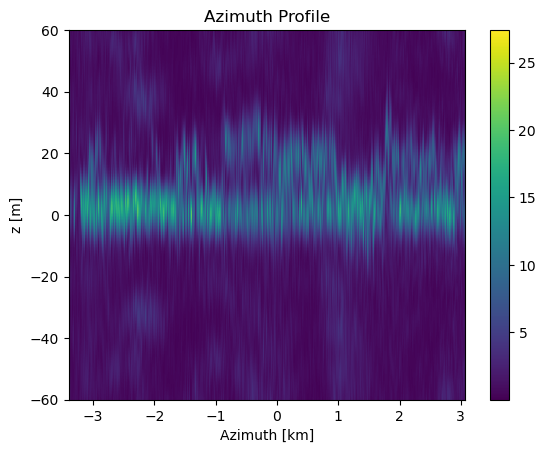

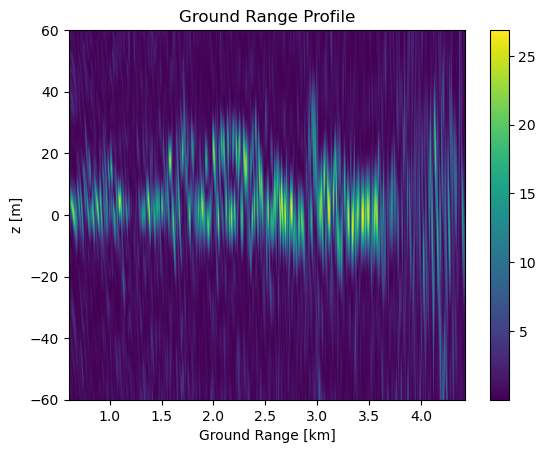

In [8]:
parent_path = r'tomosense/P' 
heading = 'NW'  
polarimetric_channel = 'HH' 


pol_map = {'HH': 0, 'HV': 1, 'VV': 2}
pol_ind = pol_map[polarimetric_channel]



# 1. Loading scene parameters
scene_params_path = os.path.join(parent_path, heading, 'Util', 'SLC', 'SceneParameters.mat')
scene_data = sio.loadmat(scene_params_path)

# Extract axes and filenames
ground_range_axis = scene_data['ground_range_axis'].flatten()
azimuth_axis = scene_data['azimuth_axis'].flatten()
filenames_kz = [f[0] for f in scene_data['filenames_kz'].flatten()]
filenames_slc = scene_data['filenames_slc'] # This is a 2D array of names
N = len(filenames_kz)
Ngr, Naz = len(ground_range_axis), len(azimuth_axis)

# 2. Loading phase-to-height factors (kz)
kz = np.zeros((Ngr, Naz, N), dtype=np.float32)
for n in range(N):
    file_path = os.path.join(parent_path, heading, 'Util', 'SLC', 'kz', filenames_kz[n])
    print(f"Loading {file_path}...")
    
    data = np.fromfile(file_path, dtype=np.float32)
    
    # Check if the 2-element header exists (16502124 vs 16502122)
    if data.size == (Ngr * Naz) + 2:
        # data[2:] skips the header. order='F' matches MATLAB's column-major format
        kz[:, :, n] = data[2:].reshape((Ngr, Naz), order='F')
    else:
        kz[:, :, n] = data.reshape((Ngr, Naz), order='F')
# 3. Loading DTMs and Sensor Trajectories
dtm_meta = sio.loadmat(os.path.join(parent_path, heading, 'Util', 'SLC', 'MetaSensingDTM.mat'))
dtm_tomo = sio.loadmat(os.path.join(parent_path, heading, 'Util', 'SLC', 'TomoDTMsr.mat'))
MetaSensingDTM = dtm_meta['MetaSensingDTM']
TomoDTMsr = dtm_tomo['TomoDTMsr']

# 4. Loading SLC images
I = np.zeros((Ngr, Naz, N), dtype=np.complex64)
for n in range(N):
    slc_name = filenames_slc[n, pol_ind][0]
    file_path = os.path.join(parent_path, heading, 'SLC', 'PoliMi', slc_name)
    print(f"Loading {file_path}...")
    
    raw_data = np.fromfile(file_path, dtype=np.float32)
    
    # Check for header. For complex data, the header is still 2 floats, 
    # but the rest is pairs of (Real, Imag)
    if raw_data.size == (Ngr * Naz * 2) + 2:
        payload = raw_data[2:]
    else:
        payload = raw_data
        
    # Reconstruct complex numbers
    real = payload[0::2]
    imag = payload[1::2]
    I[:, :, n] = (real + 1j*imag).reshape((Ngr, Naz), order='F')

# --- Tomography ---

z_axis = np.arange(-60, 61)
Nz = len(z_axis)
eps = 1e-10

# A. Azimuth profile
S_az = np.zeros((Nz, Naz))
gr_ind = int(round(Ngr / 4))
F_az = np.sum(np.abs(I[gr_ind, :, :])**2, axis=1) # Power normalization

# --- Inside Part A: Azimuth Profile Loop ---
for z_ind, z in enumerate(z_axis):
    # Fix: Subtract first, then add the new axis for broadcasting
    dtm_diff = (TomoDTMsr[gr_ind, :] - MetaSensingDTM[gr_ind, :])[:, np.newaxis]
    
    phase_corr = np.exp(-1j * kz[gr_ind, :, :] * dtm_diff)
    Igs = I[gr_ind, :, :] * phase_corr
    
    # Beamforming
    steer = np.exp(-1j * kz[gr_ind, :, :] * z)
    S_az[z_ind, :] = np.abs(np.sum(Igs * steer, axis=1))**2 / (F_az + eps)

plt.figure()
plt.imshow(S_az, extent=[azimuth_axis[0]*1e-3, azimuth_axis[-1]*1e-3, z_axis[0], z_axis[-1]], 
           aspect='auto', origin='lower')
plt.colorbar()
plt.xlabel('Azimuth [km]')
plt.ylabel('z [m]')
plt.title('Azimuth Profile')

# B. Ground range profile
S_gr = np.zeros((Nz, Ngr))
az_ind = int(round(Naz / 3))
F_gr = np.sum(np.abs(I[:, az_ind, :])**2, axis=1)

# --- Inside Part B: Ground Range Profile Loop ---
for z_ind, z in enumerate(z_axis):
    # Fix: Use az_ind and the correct range dimension (Ngr)
    dtm_diff_gr = (TomoDTMsr[:, az_ind] - MetaSensingDTM[:, az_ind])[:, np.newaxis]
    
    phase_corr_gr = np.exp(-1j * kz[:, az_ind, :] * dtm_diff_gr)
    Igs = I[:, az_ind, :] * phase_corr_gr
    
    steer = np.exp(-1j * kz[:, az_ind, :] * z)
    S_gr[z_ind, :] = np.abs(np.sum(Igs * steer, axis=1))**2 / (F_gr + eps)

plt.figure()
plt.imshow(S_gr, extent=[ground_range_axis[0]*1e-3, ground_range_axis[-1]*1e-3, z_axis[0], z_axis[-1]], 
           aspect='auto', origin='lower')
plt.colorbar()
plt.xlabel('Ground Range [km]')
plt.ylabel('z [m]')
plt.title('Ground Range Profile')
plt.show()


if heading == 'NW':
    nc_file = 'SAR_CPLX_20200722092915_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc'
else:
    nc_file = 'SAR_CPLX_20200723082647_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc'

nc_path = os.path.join(parent_path, heading, 'SLC', 'MetaSensing', nc_file)

with Dataset(nc_path, 'r') as ds:
    lat_az_axis = ds.variables['CrossRange'][:]
    lat_gr_axis = ds.variables['GroundRange'][:]
    LatImage = ds.variables['LatImage'][:]

# Find indices to crop the LatImage to match the SLC axes
def find_nearest_ind(array, value):
    return (np.abs(array - value)).argmin()

az_start = find_nearest_ind(lat_az_axis, azimuth_axis[0])
az_stop = find_nearest_ind(lat_az_axis, azimuth_axis[-1])
gr_start = find_nearest_ind(lat_gr_axis, ground_range_axis[0])
gr_stop = find_nearest_ind(lat_gr_axis, ground_range_axis[-1])
LatImage_cropped = LatImage[gr_start:gr_stop+1, az_start:az_stop+1]